# Examples for packages/scikit-learn/index.md

(simple-picture-of-the-formal-problem-of-machine-learning)=

## Simple picture of the formal problem of machine learning

<!--- plot_separator -->

This example generates simple synthetic data points and shows a
separating hyperplane on them.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import SGDClassifier
from sklearn.datasets import make_blobs

In [2]:
# we create 50 separable synthetic points
X, Y = make_blobs(n_samples=50, centers=2, random_state=0, cluster_std=0.60)

In [3]:
# fit the model
clf = SGDClassifier(loss="hinge", alpha=0.01, fit_intercept=True)
clf.fit(X, Y)

,"loss loss: {'hinge', 'log_loss', 'modified_huber', 'squared_hinge', 'perceptron', 'squared_error', 'huber', 'epsilon_insensitive', 'squared_epsilon_insensitive'}, default='hinge'The loss function to be used.- 'hinge' gives a linear SVM.- 'log_loss' gives logistic regression, a probabilistic classifier.- 'modified_huber' is another smooth loss that brings tolerance to outliers as well as probability estimates.- 'squared_hinge' is like hinge but is quadratically penalized.- 'perceptron' is the linear loss used by the perceptron algorithm.- The other losses, 'squared_error', 'huber', 'epsilon_insensitive' and 'squared_epsilon_insensitive' are designed for regression but can be useful in classification as well; see :class:`~sklearn.linear_model.SGDRegressor` for a description.More details about the losses formulas can be found in the :ref:`User Guide` and you can find a visualisation of the lossfunctions in:ref:`sphx_glr_auto_examples_linear_model_plot_sgd_loss_functions.py`.",'hinge'
,"penalty penalty: {'l2', 'l1', 'elasticnet', None}, default='l2'The penalty (aka regularization term) to be used. Defaults to 'l2'which is the standard regularizer for linear SVM models. 'l1' and'elasticnet' might bring sparsity to the model (feature selection)not achievable with 'l2'. No penalty is added when set to `None`.You can see a visualisation of the penalties in:ref:`sphx_glr_auto_examples_linear_model_plot_sgd_penalties.py`.",'l2'
,"alpha alpha: float, default=0.0001Constant that multiplies the regularization term. The higher thevalue, the stronger the regularization. Also used to compute thelearning rate when `learning_rate` is set to 'optimal'.Values must be in the range `[0.0, inf)`.",0.01
,"l1_ratio l1_ratio: float, default=0.15The Elastic Net mixing parameter, with 0 <= l1_ratio <= 1.l1_ratio=0 corresponds to L2 penalty, l1_ratio=1 to L1.Only used if `penalty` is 'elasticnet'.Values must be in the range `[0.0, 1.0]` or can be `None` if`penalty` is not `elasticnet`... versionchanged:: 1.7 `l1_ratio` can be `None` when `penalty` is not ""elasticnet"".",0.15
,"fit_intercept fit_intercept: bool, default=TrueWhether the intercept should be estimated or not. If False, thedata is assumed to be already centered.",True
,"max_iter max_iter: int, default=1000The maximum number of passes over the training data (aka epochs).It only impacts the behavior in the ``fit`` method, and not the:meth:`partial_fit` method.Values must be in the range `[1, inf)`... versionadded:: 0.19",1000
,"tol tol: float or None, default=1e-3The stopping criterion. If it is not None, training will stopwhen (loss > best_loss - tol) for ``n_iter_no_change`` consecutiveepochs.Convergence is checked against the training loss or thevalidation loss depending on the `early_stopping` parameter.Values must be in the range `[0.0, inf)`... versionadded:: 0.19",0.001
,"shuffle shuffle: bool, default=TrueWhether or not the training data should be shuffled after each epoch.",True
,"verbose verbose: int, default=0The verbosity level.Values must be in the range `[0, inf)`.",0
,"epsilon epsilon: float, default=0.1Epsilon in the epsilon-insensitive loss functions; only if `loss` is'huber', 'epsilon_insensitive', or 'squared_epsilon_insensitive'.For 'huber', determines the threshold at which it becomes lessimportant to get the prediction exactly right.For epsilon-insensitive, any differences between the current predictionand the correct label are ignored if they are less than this threshold.Values must be in the range `[0.0, inf)`.",0.1
,"n_jobs n_jobs: int, default=NoneThe number of CPUs to use to do the OVA (One Versus All, formulti-class problems) computation.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details.",None


In [4]:
# plot the line, the points, and the nearest vectors to the plane
xx = np.linspace(-1, 5, 10)
yy = np.linspace(-1, 5, 10)

In [5]:
X1, X2 = np.meshgrid(xx, yy)
Z = np.empty(X1.shape)
for (i, j), val in np.ndenumerate(X1):
    x1 = val
    x2 = X2[i, j]
    p = clf.decision_function([[x1, x2]])
    Z[i, j] = p[0]

(np.float64(-1.0),
 np.float64(5.0),
 np.float64(-1.0),
 np.float64(5.797965192816837))

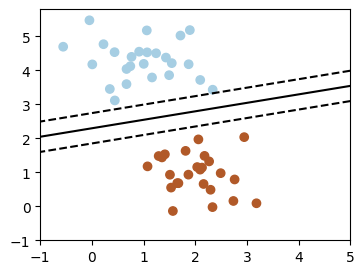

In [6]:
plt.figure(figsize=(4, 3))
ax = plt.axes()
ax.contour(
    X1, X2, Z, [-1.0, 0.0, 1.0], colors="k", linestyles=["dashed", "solid", "dashed"]
)
ax.scatter(X[:, 0], X[:, 1], c=Y, cmap="Paired")
ax.axis("tight")

(linear-regression)=

## linear_regression

<!--- plot_linear_regression -->

**A simple linear regression**

In [7]:
from sklearn.linear_model import LinearRegression

In [8]:
# x from 0 to 30
rng = np.random.default_rng()
x = 30 * rng.random((20, 1))

In [9]:
# y = a*x + b with noise
y = 0.5 * x + 1.0 + rng.normal(size=x.shape)

In [10]:
# create a linear regression model
model = LinearRegression()
model.fit(x, y)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies a different convergence criterion for the `lsqr` solver.`tol` is set as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. This parameter has no effect when fittingon dense data... versionadded:: 1.7",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary ` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False


In [11]:
# predict y from the data
x_new = np.linspace(0, 30, 100)
y_new = model.predict(x_new[:, np.newaxis])

(np.float64(-1.5),
 np.float64(31.5),
 np.float64(0.1499451465949393),
 np.float64(16.61505625725316))

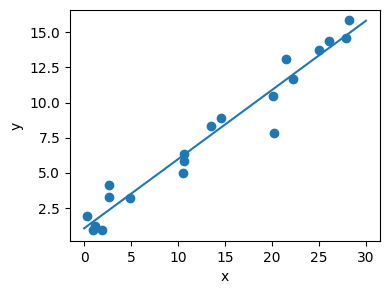

In [12]:
# plot the results
plt.figure(figsize=(4, 3))
ax = plt.axes()
ax.scatter(x, y)
ax.plot(x_new, y_new)
ax.set_xlabel("x")
ax.set_ylabel("y")
ax.axis("tight")

(plot-2d-views-of-the-iris-dataset)=

## Plot 2D views of the iris dataset

<!--- plot_iris_scatter -->

Plot a simple scatter plot of 2 features of the iris dataset.

Note that more elaborate visualization of this dataset is detailed
in the {ref}`statistics` chapter.

In [13]:
# Load the data
from sklearn.datasets import load_iris

In [14]:
iris = load_iris()

In [15]:
from matplotlib import ticker

In [16]:
# The indices of the features that we are plotting
x_index = 0
y_index = 1

In [17]:
# this formatter will label the colorbar with the correct target names
formatter = ticker.FuncFormatter(lambda i, *args: iris.target_names[int(i)])

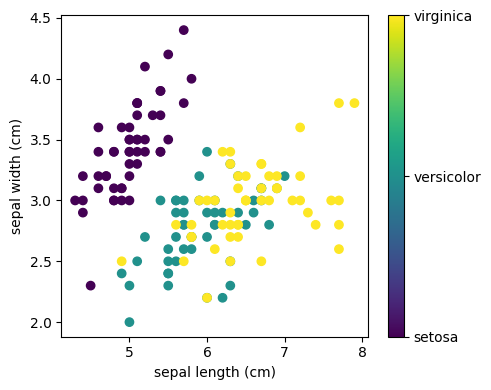

In [18]:
plt.figure(figsize=(5, 4))
plt.scatter(iris.data[:, x_index], iris.data[:, y_index], c=iris.target)
plt.colorbar(ticks=[0, 1, 2], format=formatter)
plt.xlabel(iris.feature_names[x_index])
plt.ylabel(iris.feature_names[y_index])
plt.tight_layout()

(nearest-neighbor-prediction-on-iris)=

## Nearest-neighbor prediction on iris

<!--- plot_iris_knn -->

Plot the decision boundary of nearest neighbor decision on iris, first
with a single nearest neighbor, and then using 3 nearest neighbors.

In [19]:
from sklearn import neighbors, datasets
from matplotlib.colors import ListedColormap

In [20]:
# Create color maps for 3-class classification problem, as with iris
cmap_light = ListedColormap(["#FFAAAA", "#AAFFAA", "#AAAAFF"])
cmap_bold = ListedColormap(["#FF0000", "#00FF00", "#0000FF"])

In [21]:
iris = datasets.load_iris()
X = iris.data[:, :2]  # we only take the first two features. We could
# avoid this ugly slicing by using a two-dim dataset
y = iris.target

In [22]:
knn = neighbors.KNeighborsClassifier(n_neighbors=1)
knn.fit(X, y)

,"n_neighbors n_neighbors: int, default=5Number of neighbors to use by default for :meth:`kneighbors` queries.",1
,"weights weights: {'uniform', 'distance'}, callable or None, default='uniform'Weight function used in prediction. Possible values:- 'uniform' : uniform weights. All points in each neighborhood are weighted equally.- 'distance' : weight points by the inverse of their distance. in this case, closer neighbors of a query point will have a greater influence than neighbors which are further away.- [callable] : a user-defined function which accepts an array of distances, and returns an array of the same shape containing the weights.Refer to the example entitled:ref:`sphx_glr_auto_examples_neighbors_plot_classification.py`showing the impact of the `weights` parameter on the decisionboundary.",'uniform'
,"algorithm algorithm: {'auto', 'ball_tree', 'kd_tree', 'brute'}, default='auto'Algorithm used to compute the nearest neighbors:- 'ball_tree' will use :class:`BallTree`- 'kd_tree' will use :class:`KDTree`- 'brute' will use a brute-force search.- 'auto' will attempt to decide the most appropriate algorithm based on the values passed to :meth:`fit` method.Note: fitting on sparse input will override the setting ofthis parameter, using brute force.",'auto'
,"leaf_size leaf_size: int, default=30Leaf size passed to BallTree or KDTree. This can affect thespeed of the construction and query, as well as the memoryrequired to store the tree. The optimal value depends on thenature of the problem.",30
,"p p: float, default=2Power parameter for the Minkowski metric. When p = 1, this is equivalentto using manhattan_distance (l1), and euclidean_distance (l2) for p = 2.For arbitrary p, minkowski_distance (l_p) is used. This parameter is expectedto be positive.",2
,"metric metric: str or callable, default='minkowski'Metric to use for distance computation. Default is ""minkowski"", whichresults in the standard Euclidean distance when p = 2. See thedocumentation of `scipy.spatial.distance`_ andthe metrics listed in:class:`~sklearn.metrics.pairwise.distance_metrics` for valid metricvalues.If metric is ""precomputed"", X is assumed to be a distance matrix andmust be square during fit. X may be a :term:`sparse graph`, in whichcase only ""nonzero"" elements may be considered neighbors.If metric is a callable function, it takes two arrays representing 1Dvectors as inputs and must return one value indicating the distancebetween those vectors. This works for Scipy's metrics, but is lessefficient than passing the metric name as a string.",'minkowski'
,"metric_params metric_params: dict, default=NoneAdditional keyword arguments for the metric function.",None
,"n_jobs n_jobs: int, default=NoneThe number of parallel jobs to run for neighbors search.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details.Doesn't affect :meth:`fit` method.",None


In [23]:
x_min, x_max = X[:, 0].min() - 0.1, X[:, 0].max() + 0.1
y_min, y_max = X[:, 1].min() - 0.1, X[:, 1].max() + 0.1
xx, yy = np.meshgrid(np.linspace(x_min, x_max, 100), np.linspace(y_min, y_max, 100))
Z = knn.predict(np.c_[xx.ravel(), yy.ravel()])

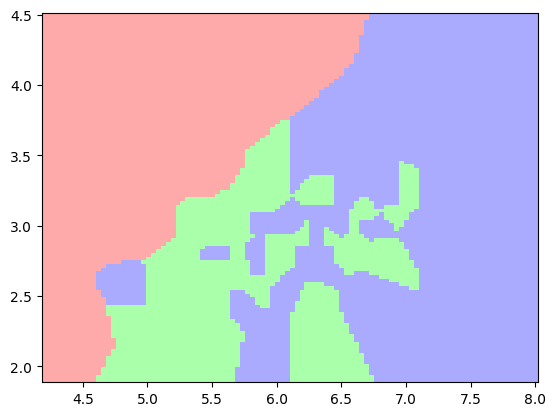

In [24]:
# Put the result into a color plot
Z = Z.reshape(xx.shape)
plt.figure()
plt.pcolormesh(xx, yy, Z, cmap=cmap_light)

(np.float64(4.12),
 np.float64(8.08),
 np.float64(1.88),
 np.float64(4.5200000000000005))

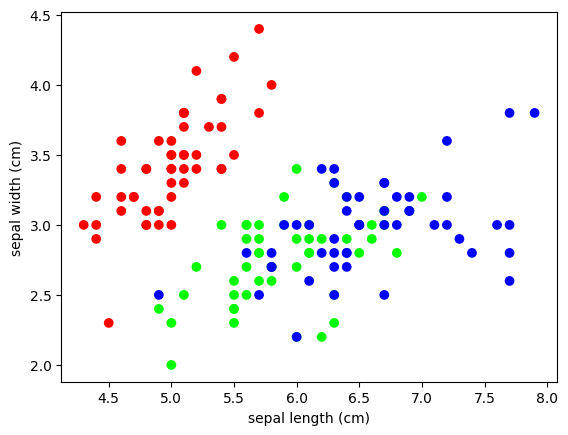

In [25]:
# Plot also the training points
plt.scatter(X[:, 0], X[:, 1], c=y, cmap=cmap_bold)
plt.xlabel("sepal length (cm)")
plt.ylabel("sepal width (cm)")
plt.axis("tight")

In [26]:
# And now, redo the analysis with 3 neighbors
knn = neighbors.KNeighborsClassifier(n_neighbors=3)
knn.fit(X, y)

,"n_neighbors n_neighbors: int, default=5Number of neighbors to use by default for :meth:`kneighbors` queries.",3
,"weights weights: {'uniform', 'distance'}, callable or None, default='uniform'Weight function used in prediction. Possible values:- 'uniform' : uniform weights. All points in each neighborhood are weighted equally.- 'distance' : weight points by the inverse of their distance. in this case, closer neighbors of a query point will have a greater influence than neighbors which are further away.- [callable] : a user-defined function which accepts an array of distances, and returns an array of the same shape containing the weights.Refer to the example entitled:ref:`sphx_glr_auto_examples_neighbors_plot_classification.py`showing the impact of the `weights` parameter on the decisionboundary.",'uniform'
,"algorithm algorithm: {'auto', 'ball_tree', 'kd_tree', 'brute'}, default='auto'Algorithm used to compute the nearest neighbors:- 'ball_tree' will use :class:`BallTree`- 'kd_tree' will use :class:`KDTree`- 'brute' will use a brute-force search.- 'auto' will attempt to decide the most appropriate algorithm based on the values passed to :meth:`fit` method.Note: fitting on sparse input will override the setting ofthis parameter, using brute force.",'auto'
,"leaf_size leaf_size: int, default=30Leaf size passed to BallTree or KDTree. This can affect thespeed of the construction and query, as well as the memoryrequired to store the tree. The optimal value depends on thenature of the problem.",30
,"p p: float, default=2Power parameter for the Minkowski metric. When p = 1, this is equivalentto using manhattan_distance (l1), and euclidean_distance (l2) for p = 2.For arbitrary p, minkowski_distance (l_p) is used. This parameter is expectedto be positive.",2
,"metric metric: str or callable, default='minkowski'Metric to use for distance computation. Default is ""minkowski"", whichresults in the standard Euclidean distance when p = 2. See thedocumentation of `scipy.spatial.distance`_ andthe metrics listed in:class:`~sklearn.metrics.pairwise.distance_metrics` for valid metricvalues.If metric is ""precomputed"", X is assumed to be a distance matrix andmust be square during fit. X may be a :term:`sparse graph`, in whichcase only ""nonzero"" elements may be considered neighbors.If metric is a callable function, it takes two arrays representing 1Dvectors as inputs and must return one value indicating the distancebetween those vectors. This works for Scipy's metrics, but is lessefficient than passing the metric name as a string.",'minkowski'
,"metric_params metric_params: dict, default=NoneAdditional keyword arguments for the metric function.",None
,"n_jobs n_jobs: int, default=NoneThe number of parallel jobs to run for neighbors search.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details.Doesn't affect :meth:`fit` method.",None


In [27]:
Z = knn.predict(np.c_[xx.ravel(), yy.ravel()])

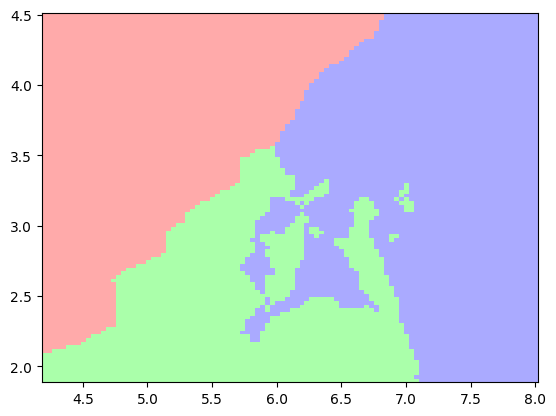

In [28]:
# Put the result into a color plot
Z = Z.reshape(xx.shape)
plt.figure()
plt.pcolormesh(xx, yy, Z, cmap=cmap_light)

(np.float64(4.12),
 np.float64(8.08),
 np.float64(1.88),
 np.float64(4.5200000000000005))

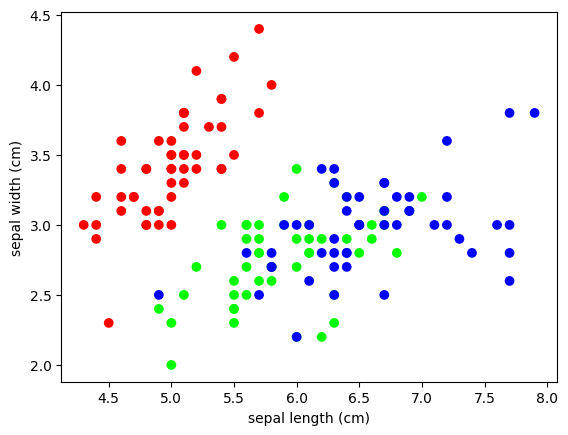

In [29]:
# Plot also the training points
plt.scatter(X[:, 0], X[:, 1], c=y, cmap=cmap_bold)
plt.xlabel("sepal length (cm)")
plt.ylabel("sepal width (cm)")
plt.axis("tight")

(plot-fitting-a-9th-order-polynomial)=

## Plot fitting a 9th order polynomial

<!--- plot_polynomial_regression -->

Fits data generated from a 9th order polynomial with model of 4th order
and 9th order polynomials, to demonstrate that often simpler models are
to be preferred

In [30]:
from matplotlib.colors import ListedColormap

In [31]:
from sklearn import linear_model

In [32]:
# Create color maps for 3-class classification problem, as with iris
cmap_light = ListedColormap(["#FFAAAA", "#AAFFAA", "#AAAAFF"])
cmap_bold = ListedColormap(["#FF0000", "#00FF00", "#0000FF"])

In [33]:
rng = np.random.default_rng(27446968)
x = 2 * rng.random(100) - 1

In [34]:
f = lambda t: 1.2 * t**2 + 0.1 * t**3 - 0.4 * t**5 - 0.5 * t**9
y = f(x) + 0.4 * rng.normal(size=100)

In [35]:
x_test = np.linspace(-1, 1, 100)

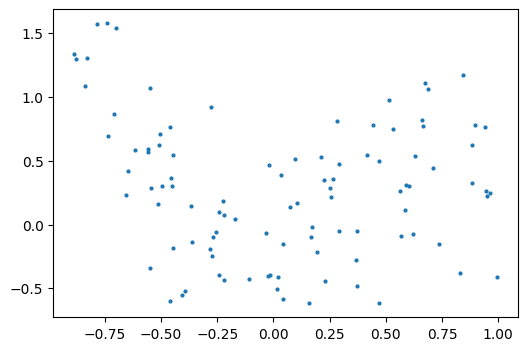

In [36]:
# The data
plt.figure(figsize=(6, 4))
plt.scatter(x, y, s=4)

Text(0.5, 1.0, 'Fitting a 4th and a 9th order polynomial')

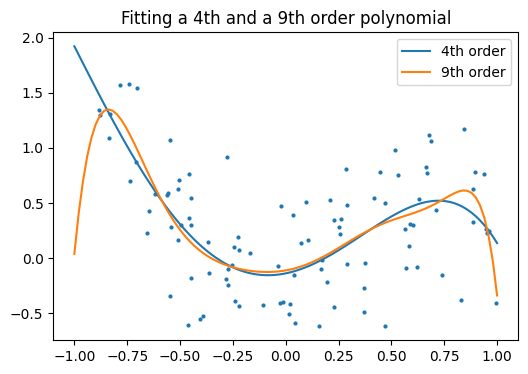

In [37]:
# Fitting 4th and 9th order polynomials
#
# For this we need to engineer features: the n_th powers of x:
plt.figure(figsize=(6, 4))
plt.scatter(x, y, s=4)

X = np.array([x**i for i in range(5)]).T
X_test = np.array([x_test**i for i in range(5)]).T
regr = linear_model.LinearRegression()
regr.fit(X, y)
plt.plot(x_test, regr.predict(X_test), label="4th order")

X = np.array([x**i for i in range(10)]).T
X_test = np.array([x_test**i for i in range(10)]).T
regr = linear_model.LinearRegression()
regr.fit(X, y)
plt.plot(x_test, regr.predict(X_test), label="9th order")

plt.legend(loc="best")
plt.axis("tight")
plt.title("Fitting a 4th and a 9th order polynomial")

Text(0.5, 1.0, 'Ground truth (9th order polynomial)')

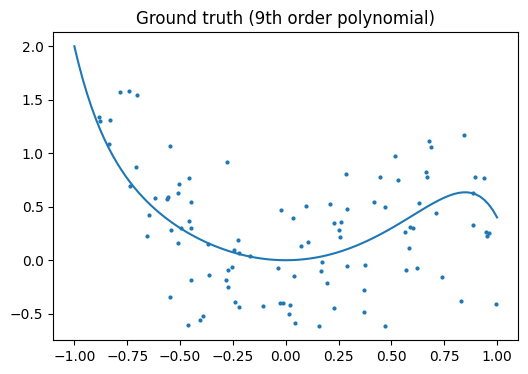

In [38]:
# Ground truth
plt.figure(figsize=(6, 4))
plt.scatter(x, y, s=4)
plt.plot(x_test, f(x_test), label="truth")
plt.axis("tight")
plt.title("Ground truth (9th order polynomial)")

(simple-visualization-and-classification-of-the-digits-dataset)=

## Simple visualization and classification of the digits dataset

<!--- plot_digits_simple_classif -->

Plot the first few samples of the digits dataset and a 2D representation
built using PCA, then do a simple classification

In [39]:
from sklearn.datasets import load_digits

In [40]:
digits = load_digits()

In [41]:
# Plot the data: images of digits
# -------------------------------
#
# Each data in a 8x8 image

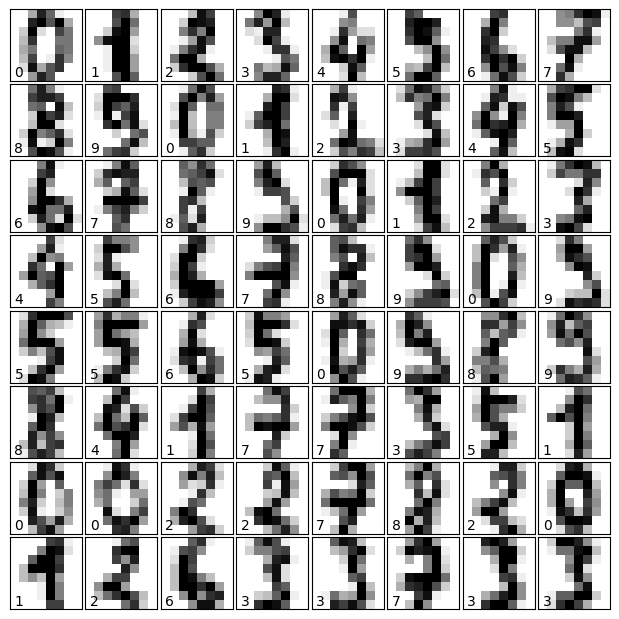

In [42]:
fig = plt.figure(figsize=(6, 6))  # figure size in inches
fig.subplots_adjust(left=0, right=1, bottom=0, top=1, hspace=0.05, wspace=0.05)
for i in range(64):
    ax = fig.add_subplot(8, 8, i + 1, xticks=[], yticks=[])
    ax.imshow(digits.images[i], cmap="binary", interpolation="nearest")
    # label the image with the target value
    ax.text(0, 7, str(digits.target[i]))

Plot a projection on the 2 first principal axis

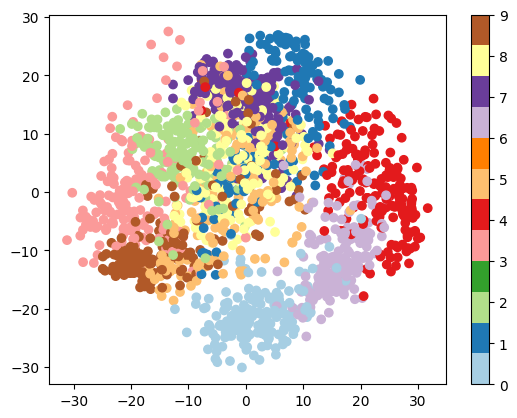

In [43]:
from sklearn.decomposition import PCA

plt.figure()
pca = PCA(n_components=2)
proj = pca.fit_transform(digits.data)
plt.scatter(proj[:, 0], proj[:, 1], c=digits.target, cmap="Paired")
plt.colorbar()

Classify with Gaussian naive Bayes

In [44]:
from sklearn.naive_bayes import GaussianNB
from sklearn.model_selection import train_test_split

In [45]:
# split the data into training and validation sets
X_train, X_test, y_train, y_test = train_test_split(digits.data, digits.target)

In [46]:
# train the model
clf = GaussianNB()
clf.fit(X_train, y_train)

,"priors priors: array-like of shape (n_classes,), default=NonePrior probabilities of the classes. If specified, the priors are notadjusted according to the data.",None
,"var_smoothing var_smoothing: float, default=1e-9Portion of the largest variance of all features that is added tovariances for calculation stability... versionadded:: 0.20",1e-09


In [47]:
# use the model to predict the labels of the test data
predicted = clf.predict(X_test)
expected = y_test

In [48]:
# Plot the prediction
fig = plt.figure(figsize=(6, 6))  # figure size in inches
fig.subplots_adjust(left=0, right=1, bottom=0, top=1, hspace=0.05, wspace=0.05)

<Figure size 600x600 with 0 Axes>

In [49]:
# plot the digits: each image is 8x8 pixels
for i in range(64):
    ax = fig.add_subplot(8, 8, i + 1, xticks=[], yticks=[])
    ax.imshow(X_test.reshape(-1, 8, 8)[i], cmap="binary", interpolation="nearest")

    # label the image with the target value
    if predicted[i] == expected[i]:
        ax.text(0, 7, str(predicted[i]), color="green")
    else:
        ax.text(0, 7, str(predicted[i]), color="red")

In [50]:
# Quantify the performance
# ------------------------
#
# First print the number of correct matches
matches = predicted == expected
print(matches.sum())

# The total number of data points
print(len(matches))

#  And now, the ratio of correct predictions
matches.sum() / float(len(matches))

369
450


np.float64(0.82)

In [51]:
# Print the classification report
from sklearn import metrics

In [52]:
print(metrics.classification_report(expected, predicted))

              precision    recall  f1-score   support

           0       1.00      1.00      1.00        44
           1       0.79      0.78      0.78        40
           2       0.88      0.53      0.66        40
           3       0.88      0.70      0.78        53
           4       0.97      0.80      0.88        44
           5       0.87      0.94      0.90        48
           6       0.94      1.00      0.97        32
           7       0.71      1.00      0.83        47
           8       0.57      0.88      0.69        49
           9       0.89      0.64      0.75        53

    accuracy                           0.82       450
   macro avg       0.85      0.83      0.82       450
weighted avg       0.85      0.82      0.82       450



In [53]:
# Print the confusion matrix
print(metrics.confusion_matrix(expected, predicted))

[[44  0  0  0  0  0  0  0  0  0]
 [ 0 31  0  0  0  0  0  1  6  2]
 [ 0  4 21  1  0  0  0  0 14  0]
 [ 0  1  2 37  0  3  0  4  5  1]
 [ 0  0  0  0 35  1  1  7  0  0]
 [ 0  0  0  1  0 45  0  0  1  1]
 [ 0  0  0  0  0  0 32  0  0  0]
 [ 0  0  0  0  0  0  0 47  0  0]
 [ 0  2  1  0  0  1  0  2 43  0]
 [ 0  1  0  3  1  2  1  5  6 34]]


(a-simple-regression-analysis-on-the-california-housing-data)=

## A simple regression analysis on the California housing data

<!--- plot_california_prediction -->

Here we perform a simple regression analysis on the California housing
data, exploring two types of regressors.

In [54]:
from sklearn.datasets import fetch_california_housing

In [55]:
data = fetch_california_housing(as_frame=True)

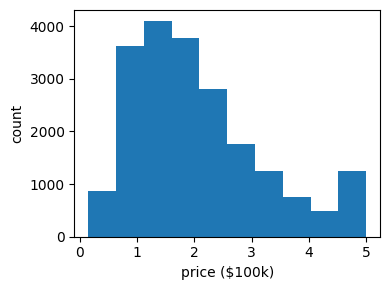

In [56]:
# Print a histogram of the quantity to predict: price
plt.figure(figsize=(4, 3))
plt.hist(data.target)
plt.xlabel("price ($100k)")
plt.ylabel("count")
plt.tight_layout()

Print the joint histogram for each feature

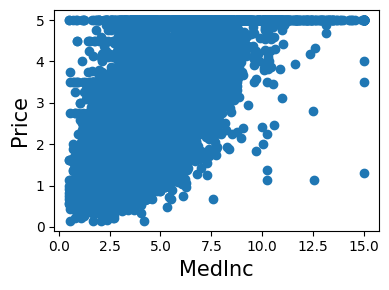

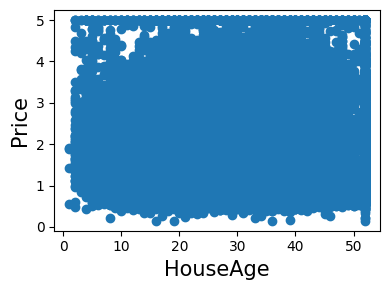

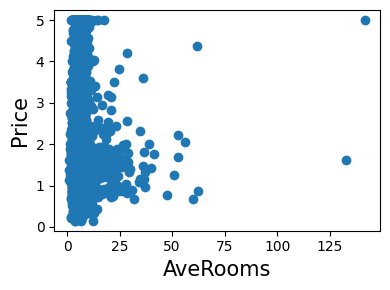

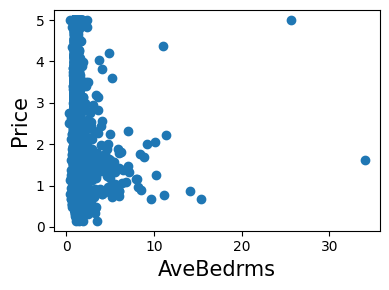

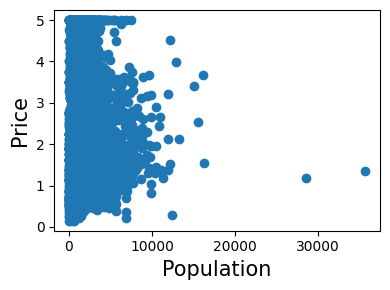

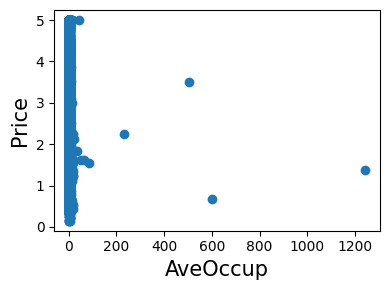

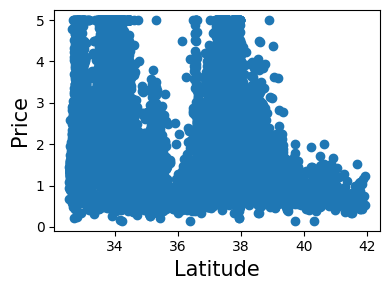

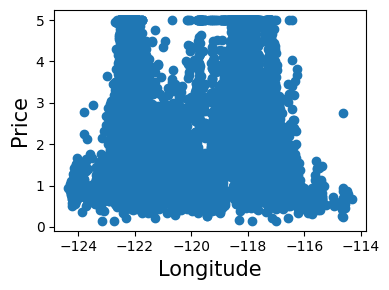

In [57]:
for index, feature_name in enumerate(data.feature_names):
    plt.figure(figsize=(4, 3))
    plt.scatter(data.data[feature_name], data.target)
    plt.ylabel("Price", size=15)
    plt.xlabel(feature_name, size=15)
    plt.tight_layout()

### Simple prediction

In [58]:
from sklearn.model_selection import train_test_split

In [59]:
X_train, X_test, y_train, y_test = train_test_split(data.data, data.target)

In [60]:
from sklearn.linear_model import LinearRegression

In [61]:
clf = LinearRegression()
clf.fit(X_train, y_train)
predicted = clf.predict(X_test)
expected = y_test

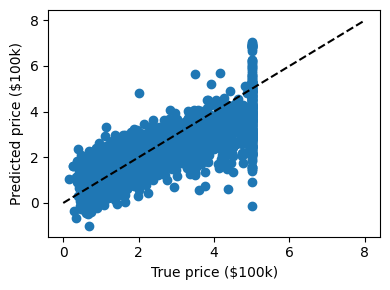

In [62]:
plt.figure(figsize=(4, 3))
plt.scatter(expected, predicted)
plt.plot([0, 8], [0, 8], "--k")
plt.axis("tight")
plt.xlabel("True price ($100k)")
plt.ylabel("Predicted price ($100k)")
plt.tight_layout()

Prediction with gradient boosted tree

In [63]:
from sklearn.ensemble import GradientBoostingRegressor

In [64]:
clf = GradientBoostingRegressor()
clf.fit(X_train, y_train)

,"loss loss: {'squared_error', 'absolute_error', 'huber', 'quantile'}, default='squared_error'Loss function to be optimized. 'squared_error' refers to the squarederror for regression. 'absolute_error' refers to the absolute error ofregression and is a robust loss function. 'huber' is acombination of the two. 'quantile' allows quantile regression (use`alpha` to specify the quantile).See:ref:`sphx_glr_auto_examples_ensemble_plot_gradient_boosting_quantile.py`for an example that demonstrates quantile regression for creatingprediction intervals with `loss='quantile'`.",'squared_error'
,"learning_rate learning_rate: float, default=0.1Learning rate shrinks the contribution of each tree by `learning_rate`.There is a trade-off between learning_rate and n_estimators.Values must be in the range `[0.0, inf)`.",0.1
,"n_estimators n_estimators: int, default=100The number of boosting stages to perform. Gradient boostingis fairly robust to over-fitting so a large number usuallyresults in better performance.Values must be in the range `[1, inf)`.",100
,"subsample subsample: float, default=1.0The fraction of samples to be used for fitting the individual baselearners. If smaller than 1.0 this results in Stochastic GradientBoosting. `subsample` interacts with the parameter `n_estimators`.Choosing `subsample < 1.0` leads to a reduction of varianceand an increase in bias.Values must be in the range `(0.0, 1.0]`.",1.0
,"criterion criterion: {'friedman_mse', 'squared_error'}, default='friedman_mse'The function to measure the quality of a split. Supported criteria are""friedman_mse"" for the mean squared error with improvement score byFriedman, ""squared_error"" for mean squared error. The default value of""friedman_mse"" is generally the best as it can provide a betterapproximation in some cases... versionadded:: 0.18",'friedman_mse'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, values must be in the range `[2, inf)`.- If float, values must be in the range `(0.0, 1.0]` and `min_samples_split` will be `ceil(min_samples_split * n_samples)`... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, values must be in the range `[1, inf)`.- If float, values must be in the range `(0.0, 1.0)` and `min_samples_leaf` will be `ceil(min_samples_leaf * n_samples)`... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.Values must be in the range `[0.0, 0.5]`.",0.0
,"max_depth max_depth: int or None, default=3Maximum depth of the individual regression estimators. The maximumdepth limits the number of nodes in the tree. Tune this parameterfor best performance; the best value depends on the interactionof the input variables. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.If int, values must be in the range `[1, inf)`.",3
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.Values must be in the range `[0.0, inf)`.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft 

In [65]:
predicted = clf.predict(X_test)
expected = y_test

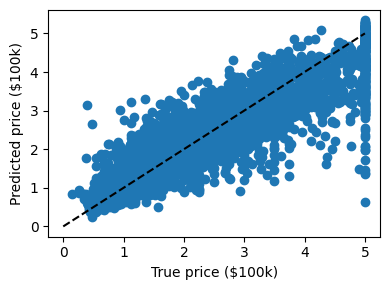

In [66]:
plt.figure(figsize=(4, 3))
plt.scatter(expected, predicted)
plt.plot([0, 5], [0, 5], "--k")
plt.axis("tight")
plt.xlabel("True price ($100k)")
plt.ylabel("Predicted price ($100k)")
plt.tight_layout()

In [67]:
# Print the error rate
print(f"RMS: {np.sqrt(np.mean((predicted - expected) ** 2))!r} ")

RMS: np.float64(0.5318724484727005) 


(measuring-decision-tree-performance)=

## Measuring Decision Tree performance

<!--- plot_measuring_performance -->

Demonstrates overfit when testing on train set.

Get the data

In [68]:
from sklearn.datasets import fetch_california_housing

In [69]:
data = fetch_california_housing(as_frame=True)

In [70]:
# Train and test a model
from sklearn.tree import DecisionTreeRegressor

In [71]:
clf = DecisionTreeRegressor().fit(data.data, data.target)

In [72]:
predicted = clf.predict(data.data)
expected = data.target

Plot predicted as a function of expected

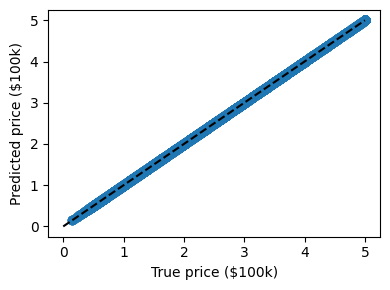

In [73]:
plt.figure(figsize=(4, 3))
plt.scatter(expected, predicted)
plt.plot([0, 5], [0, 5], "--k")
plt.axis("tight")
plt.xlabel("True price ($100k)")
plt.ylabel("Predicted price ($100k)")
plt.tight_layout()

Pretty much no errors!

This is too good to be true: we are testing the model on the train
data, which is not a measure of generalization.

**The results are not valid**

(linear-model-cv)=

## linear_model_cv

<!--- plot_linear_model_cv -->

Use the RidgeCV and LassoCV to set the regularization parameter

In [74]:
# Load the diabetes dataset
from sklearn.datasets import load_diabetes

In [75]:
data = load_diabetes()
X, y = data.data, data.target
print(X.shape)

(442, 10)


In [76]:
# Compute the cross-validation score with the default hyper-parameters
from sklearn.model_selection import cross_val_score
from sklearn.linear_model import Ridge, Lasso

In [77]:
for Model in [Ridge, Lasso]:
    model = Model()
    print(f"{Model.__name__}: {cross_val_score(model, X, y).mean()}")

Ridge: 0.410174971340889
Lasso: 0.3375593674654274


In [78]:
# We compute the cross-validation score as a function of alpha, the
# strength of the regularization for Lasso and Ridge

In [79]:
alphas = np.logspace(-3, -1, 30)

In [80]:
plt.figure(figsize=(5, 3))

<Figure size 500x300 with 0 Axes>

<Figure size 500x300 with 0 Axes>

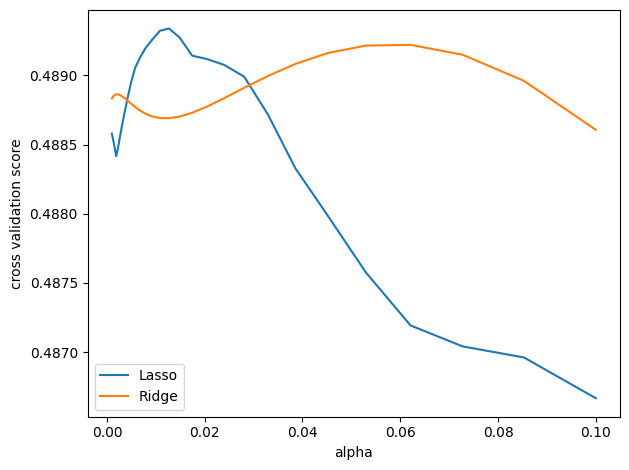

In [81]:
for Model in [Lasso, Ridge]:
    scores = [cross_val_score(Model(alpha), X, y, cv=3).mean() for alpha in alphas]
    plt.plot(alphas, scores, label=Model.__name__)
plt.legend(loc="lower left")
plt.xlabel("alpha")
plt.ylabel("cross validation score")
plt.tight_layout()

(pca)=

## pca

<!--- plot_pca -->

Demo PCA in 2D

In [82]:
# Load the iris data
from sklearn import datasets

iris = datasets.load_iris()
X = iris.data
y = iris.target

In [83]:
# Fit a PCA
from sklearn.decomposition import PCA

In [84]:
pca = PCA(n_components=2, whiten=True)
pca.fit(X)

,"n_components n_components: int, float or 'mle', default=NoneNumber of components to keep.if n_components is not set all components are kept:: n_components == min(n_samples, n_features)If ``n_components == 'mle'`` and ``svd_solver == 'full'``, Minka'sMLE is used to guess the dimension. Use of ``n_components == 'mle'``will interpret ``svd_solver == 'auto'`` as ``svd_solver == 'full'``.If ``0 < n_components < 1`` and ``svd_solver == 'full'``, select thenumber of components such that the amount of variance that needs to beexplained is greater than the percentage specified by n_components.If ``svd_solver == 'arpack'``, the number of components must bestrictly less than the minimum of n_features and n_samples.Hence, the None case results in:: n_components == min(n_samples, n_features) - 1",2
,"copy copy: bool, default=TrueIf False, data passed to fit are overwritten and runningfit(X).transform(X) will not yield the expected results,use fit_transform(X) instead.",True
,"whiten whiten: bool, default=FalseWhen True (False by default) the `components_` vectors are multipliedby the square root of n_samples and then divided by the singular valuesto ensure uncorrelated outputs with unit component-wise variances.Whitening will remove some information from the transformed signal(the relative variance scales of the components) but can sometimeimprove the predictive accuracy of the downstream estimators bymaking their data respect some hard-wired assumptions.",True
,"svd_solver svd_solver: {'auto', 'full', 'covariance_eigh', 'arpack', 'randomized'}, default='auto'""auto"" : The solver is selected by a default 'auto' policy is based on `X.shape` and `n_components`: if the input data has fewer than 1000 features and more than 10 times as many samples, then the ""covariance_eigh"" solver is used. Otherwise, if the input data is larger than 500x500 and the number of components to extract is lower than 80% of the smallest dimension of the data, then the more efficient ""randomized"" method is selected. Otherwise the exact ""full"" SVD is computed and optionally truncated afterwards.""full"" : Run exact full SVD calling the standard LAPACK solver via `scipy.linalg.svd` and select the components by postprocessing""covariance_eigh"" : Precompute the covariance matrix (on centered data), run a classical eigenvalue decomposition on the covariance matrix typically using LAPACK and select the components by postprocessing. This solver is very efficient for n_samples >> n_features and small n_features. It is, however, not tractable otherwise for large n_features (large memory footprint required to materialize the covariance matrix). Also note that compared to the ""full"" solver, this solver effectively doubles the condition number and is therefore less numerical stable (e.g. on input data with a large range of singular values).""arpack"" : Run SVD truncated to `n_components` calling ARPACK solver via `scipy.sparse.linalg.svds`. It requires strictly `0 < n_components < min(X.shape)`""randomized"" : Run randomized SVD by the method of Halko et al... versionadded:: 0.18.0.. versionchanged:: 1.5 Added the 'covariance_eigh' solver.",'auto'
,"tol tol: float, default=0.0Tolerance for singular values computed by svd_solver == 'arpack'.Must be of range [0.0, infinity)... versionadded:: 0.18.0",0.0
,"iterated_power iterated_power: int or 'auto', default='auto'Number of iterations for the power method computed bysvd_solver == 'randomized'.Must be of range [0, infinity)... versionadded:: 0.18.0",'auto'
,"n_oversamples n_oversamples: int, default=10This parameter is only relevant when `svd_solver=""randomized""`.It corresponds to the additional number of random vectors to sample therange of `X` so as to ensure proper conditioning. See:func:`~sklearn.utils.extmath.randomized_svd` for more details... versionadded:: 1.1",10
,"power_iteration_normalizer power_iteration_normalizer: {'auto', 'QR', 'LU', 'none'}, default='auto'Power iteration normalizer for randomized SVD s

In [85]:
# Project the data in 2D
X_pca = pca.transform(X)

In [86]:
# Visualize the data
target_ids = range(len(iris.target_names))

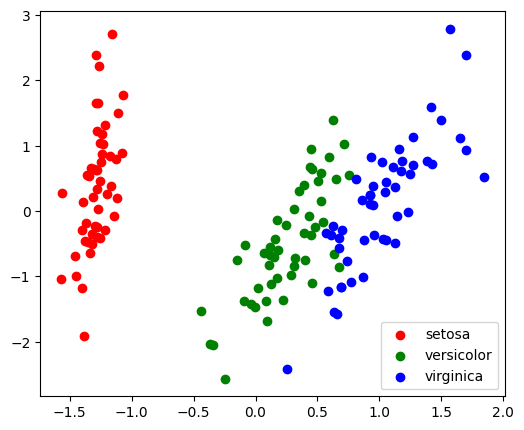

In [87]:
plt.figure(figsize=(6, 5))
for i, c, label in zip(target_ids, "rgbcmykw", iris.target_names, strict=False):
    plt.scatter(X_pca[y == i, 0], X_pca[y == i, 1], c=c, label=label)
plt.legend()

(tsne)=

## tSNE to visualize digits

<!--- plot_tsne -->

Here we use {class}`sklearn.manifold.TSNE` to visualize the digits
datasets. Indeed, the digits are vectors in a 8\*8 = 64 dimensional space.
We want to project them in 2D for visualization. tSNE is often a good
solution, as it groups and separates data points based on their local
relationship.

In [88]:
# Load the iris data
from sklearn import datasets

In [89]:
digits = datasets.load_digits()
# Take the first 500 data points: it's hard to see 1500 points
X = digits.data[:500]
y = digits.target[:500]

In [90]:
# Fit and transform with a TSNE
from sklearn.manifold import TSNE

In [91]:
tsne = TSNE(n_components=2, random_state=0)

In [92]:
# Project the data in 2D
X_2d = tsne.fit_transform(X)

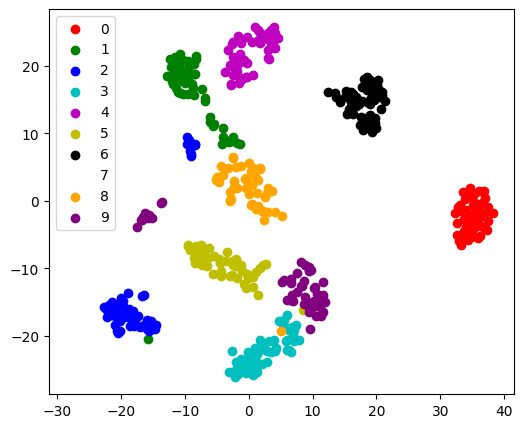

In [93]:
# Visualize the data
target_ids = range(len(digits.target_names))
plt.figure(figsize=(6, 5))
colors = "r", "g", "b", "c", "m", "y", "k", "w", "orange", "purple"
for i, c, label in zip(target_ids, colors, digits.target_names, strict=True):
    plt.scatter(X_2d[y == i, 0], X_2d[y == i, 1], c=c, label=label)
plt.legend()

(bias-variance)=

## Bias and variance of polynomial fit

<!--- plot_bias_variance -->

Demo overfitting, underfitting, and validation and learning curves with
polynomial regression.

Fit polynomes of different degrees to a dataset: for too small a degree,
the model _underfits_, while for too large a degree, it overfits.

In [94]:
def generating_func(x, rng=None, error=0.5):
    rng = np.random.default_rng(rng)
    return rng.normal(10 - 1.0 / (x + 0.1), error)

In [95]:
# A polynomial regression
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import PolynomialFeatures

A simple figure to illustrate the problem

In [96]:
n_samples = 8

In [97]:
rng = np.random.default_rng(27446968)
x = 10 ** np.linspace(-2, 0, n_samples)
y = generating_func(x, rng=rng)

In [98]:
x_test = np.linspace(-0.2, 1.2, 1000)

In [99]:
titles = ["d = 1 (under-fit; high bias)", "d = 2", "d = 6 (over-fit; high variance)"]
degrees = [1, 2, 6]

In [100]:
fig = plt.figure(figsize=(9, 3.5))
fig.subplots_adjust(left=0.06, right=0.98, bottom=0.15, top=0.85, wspace=0.05)

<Figure size 900x350 with 0 Axes>

In [101]:
for i, d in enumerate(degrees):
    ax = fig.add_subplot(131 + i, xticks=[], yticks=[])
    ax.scatter(x, y, marker="x", c="k", s=50)

    model = make_pipeline(PolynomialFeatures(d), LinearRegression())
    model.fit(x[:, np.newaxis], y)
    ax.plot(x_test, model.predict(x_test[:, np.newaxis]), "-b")

    ax.set_xlim(-0.2, 1.2)
    ax.set_ylim(0, 12)
    ax.set_xlabel("house size")
    if i == 0:
        ax.set_ylabel("price")

    ax.set_title(titles[i])

In [102]:
# Generate a larger dataset
from sklearn.model_selection import train_test_split

In [103]:
n_samples = 200
test_size = 0.4
error = 1.0

In [104]:
# randomly sample the data
x = rng.random(n_samples)
y = generating_func(x, rng=rng, error=error)

In [105]:
# split into training, validation, and testing sets.
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=test_size)

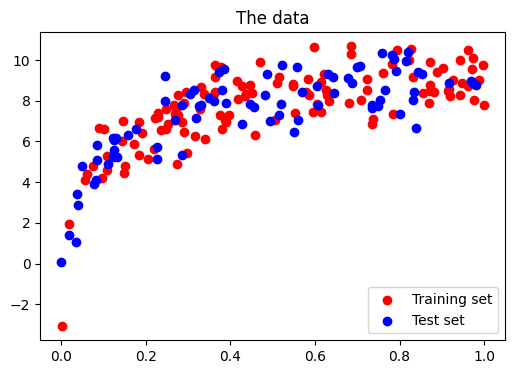

In [106]:
# show the training and validation sets
plt.figure(figsize=(6, 4))
plt.scatter(x_train, y_train, color="red", label="Training set")
plt.scatter(x_test, y_test, color="blue", label="Test set")
plt.title("The data")
plt.legend(loc="best")

In [107]:
# Plot a validation curve
from sklearn.model_selection import validation_curve

In [108]:
degrees = list(range(1, 21))

In [109]:
model = make_pipeline(PolynomialFeatures(), LinearRegression())

In [110]:
# The parameter to vary is the "degrees" on the pipeline step
# "polynomialfeatures"
train_scores, validation_scores = validation_curve(
    model,
    x[:, np.newaxis],
    y,
    param_name="polynomialfeatures__degree",
    param_range=degrees,
)

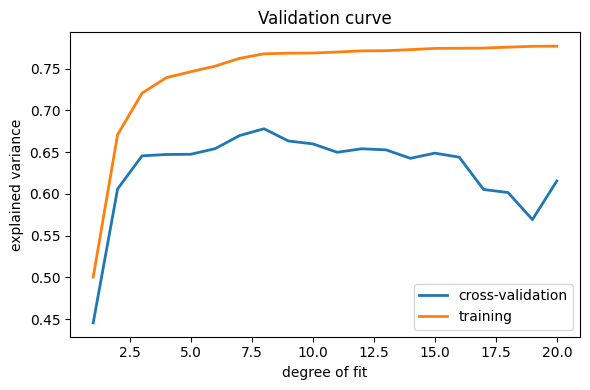

In [111]:
# Plot the mean train error and validation error across folds
plt.figure(figsize=(6, 4))
plt.plot(degrees, validation_scores.mean(axis=1), lw=2, label="cross-validation")
plt.plot(degrees, train_scores.mean(axis=1), lw=2, label="training")
plt.legend(loc="best")
plt.xlabel("degree of fit")
plt.ylabel("explained variance")
plt.title("Validation curve")
plt.tight_layout()

## Learning curves

Plot train and test error with an increasing number of samples

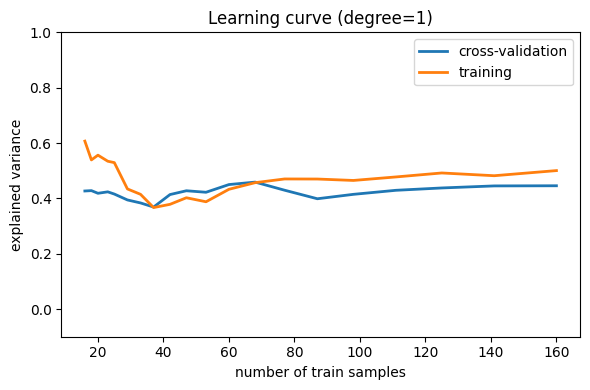

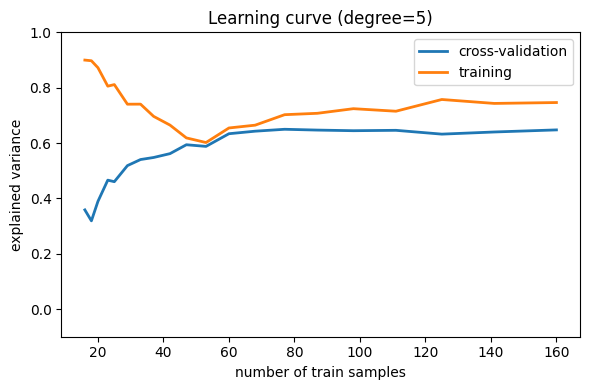

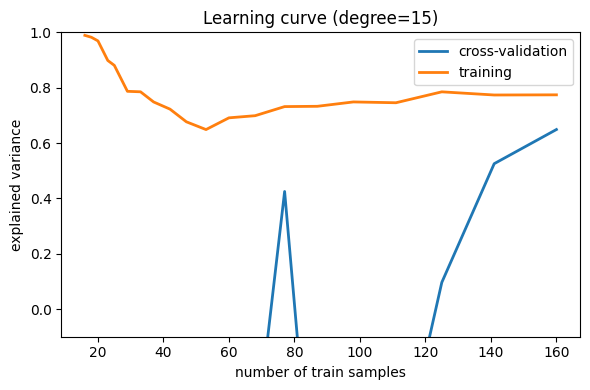

In [112]:
# A learning curve for d=1, 5, 15
for d in [1, 5, 15]:
    model = make_pipeline(PolynomialFeatures(degree=d), LinearRegression())

    from sklearn.model_selection import learning_curve

    train_sizes, train_scores, validation_scores = learning_curve(
        model, x[:, np.newaxis], y, train_sizes=np.logspace(-1, 0, 20)
    )

    # Plot the mean train error and validation error across folds
    plt.figure(figsize=(6, 4))
    plt.plot(
        train_sizes, validation_scores.mean(axis=1), lw=2, label="cross-validation"
    )
    plt.plot(train_sizes, train_scores.mean(axis=1), lw=2, label="training")
    plt.ylim(ymin=-0.1, ymax=1)

    plt.legend(loc="best")
    plt.xlabel("number of train samples")
    plt.ylabel("explained variance")
    plt.title(f"Learning curve (degree={d})")
    plt.tight_layout()

## Other examples

(tutorial-diagrams)=

### Tutorial Diagrams

<!--- plot_ML_flow_chart -->

This script plots the flow-charts used in the scikit-learn tutorials.

In [113]:
from matplotlib.patches import Circle, Rectangle, Polygon, Arrow, FancyArrow

In [114]:
def create_base(box_bg="#CCCCCC", arrow1="#88CCFF", arrow2="#88FF88", supervised=True):
    fig = plt.figure(figsize=(9, 6), facecolor="w")
    ax = plt.axes((0, 0, 1, 1), xticks=[], yticks=[], frameon=False)
    ax.set_xlim(0, 9)
    ax.set_ylim(0, 6)

    patches = [
        Rectangle((0.3, 3.6), 1.5, 1.8, zorder=1, fc=box_bg),
        Rectangle((0.5, 3.8), 1.5, 1.8, zorder=2, fc=box_bg),
        Rectangle((0.7, 4.0), 1.5, 1.8, zorder=3, fc=box_bg),
        Rectangle((2.9, 3.6), 0.2, 1.8, fc=box_bg),
        Rectangle((3.1, 3.8), 0.2, 1.8, fc=box_bg),
        Rectangle((3.3, 4.0), 0.2, 1.8, fc=box_bg),
        Rectangle((0.3, 0.2), 1.5, 1.8, fc=box_bg),
        Rectangle((2.9, 0.2), 0.2, 1.8, fc=box_bg),
        Circle((5.5, 3.5), 1.0, fc=box_bg),
        Polygon([[5.5, 1.7], [6.1, 1.1], [5.5, 0.5], [4.9, 1.1]], fc=box_bg),
        FancyArrow(
            2.3, 4.6, 0.35, 0, fc=arrow1, width=0.25, head_width=0.5, head_length=0.2
        ),
        FancyArrow(
            3.75, 4.2, 0.5, -0.2, fc=arrow1, width=0.25, head_width=0.5, head_length=0.2
        ),
        FancyArrow(
            5.5, 2.4, 0, -0.4, fc=arrow1, width=0.25, head_width=0.5, head_length=0.2
        ),
        FancyArrow(
            2.0, 1.1, 0.5, 0, fc=arrow2, width=0.25, head_width=0.5, head_length=0.2
        ),
        FancyArrow(
            3.3, 1.1, 1.3, 0, fc=arrow2, width=0.25, head_width=0.5, head_length=0.2
        ),
        FancyArrow(
            6.2, 1.1, 0.8, 0, fc=arrow2, width=0.25, head_width=0.5, head_length=0.2
        ),
    ]

    if supervised:
        patches += [
            Rectangle((0.3, 2.4), 1.5, 0.5, zorder=1, fc=box_bg),
            Rectangle((0.5, 2.6), 1.5, 0.5, zorder=2, fc=box_bg),
            Rectangle((0.7, 2.8), 1.5, 0.5, zorder=3, fc=box_bg),
            FancyArrow(
                2.3, 2.9, 2.0, 0, fc=arrow1, width=0.25, head_width=0.5, head_length=0.2
            ),
            Rectangle((7.3, 0.85), 1.5, 0.5, fc=box_bg),
        ]
    else:
        patches += [Rectangle((7.3, 0.2), 1.5, 1.8, fc=box_bg)]

    for p in patches:
        ax.add_patch(p)

    plt.text(
        1.45,
        4.9,
        "Training\nText,\nDocuments,\nImages,\netc.",
        ha="center",
        va="center",
        fontsize=14,
    )

    plt.text(3.6, 4.9, "Feature\nVectors", ha="left", va="center", fontsize=14)

    plt.text(
        5.5, 3.5, "Machine\nLearning\nAlgorithm", ha="center", va="center", fontsize=14
    )

    plt.text(
        1.05,
        1.1,
        "New Text,\nDocument,\nImage,\netc.",
        ha="center",
        va="center",
        fontsize=14,
    )

    plt.text(3.3, 1.7, "Feature\nVector", ha="left", va="center", fontsize=14)

    plt.text(5.5, 1.1, "Predictive\nModel", ha="center", va="center", fontsize=12)

    if supervised:
        plt.text(1.45, 3.05, "Labels", ha="center", va="center", fontsize=14)

        plt.text(8.05, 1.1, "Expected\nLabel", ha="center", va="center", fontsize=14)
        plt.text(
            8.8, 5.8, "Supervised Learning Model", ha="right", va="top", fontsize=18
        )

    else:
        plt.text(
            8.05,
            1.1,
            "Likelihood\nor Cluster ID\nor Better\nRepresentation",
            ha="center",
            va="center",
            fontsize=12,
        )
        plt.text(
            8.8, 5.8, "Unsupervised Learning Model", ha="right", va="top", fontsize=18
        )

In [115]:
def plot_supervised_chart(annotate=False):
    create_base(supervised=True)
    if annotate:
        fontdict = {"color": "r", "weight": "bold", "size": 14}
        plt.text(
            1.9,
            4.55,
            "X = vec.fit_transform(input)",
            fontdict=fontdict,
            rotation=20,
            ha="left",
            va="bottom",
        )
        plt.text(
            3.7,
            3.2,
            "clf.fit(X, y)",
            fontdict=fontdict,
            rotation=20,
            ha="left",
            va="bottom",
        )
        plt.text(
            1.7,
            1.5,
            "X_new = vec.transform(input)",
            fontdict=fontdict,
            rotation=20,
            ha="left",
            va="bottom",
        )
        plt.text(
            6.1,
            1.5,
            "y_new = clf.predict(X_new)",
            fontdict=fontdict,
            rotation=20,
            ha="left",
            va="bottom",
        )

In [116]:
def plot_unsupervised_chart():
    create_base(supervised=False)

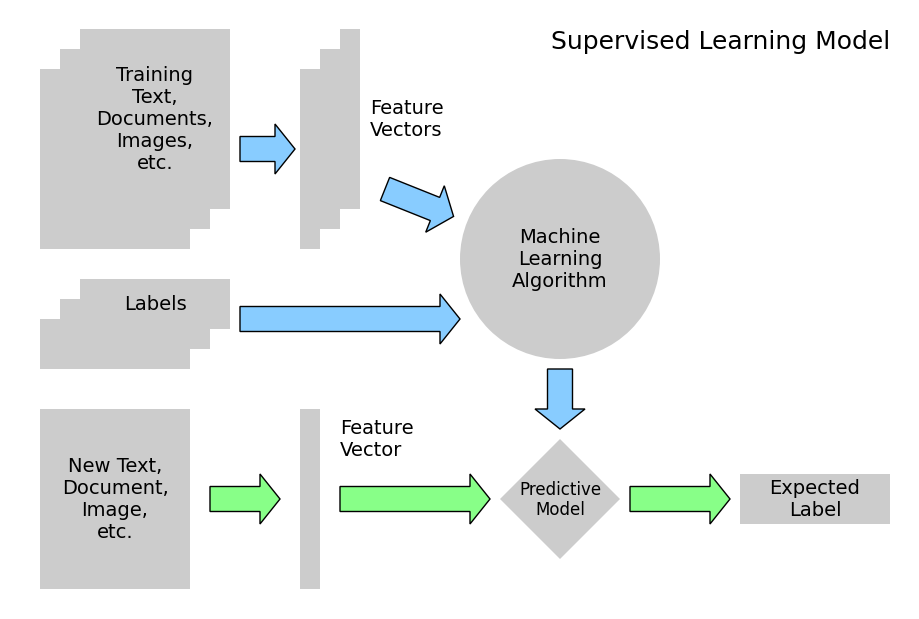

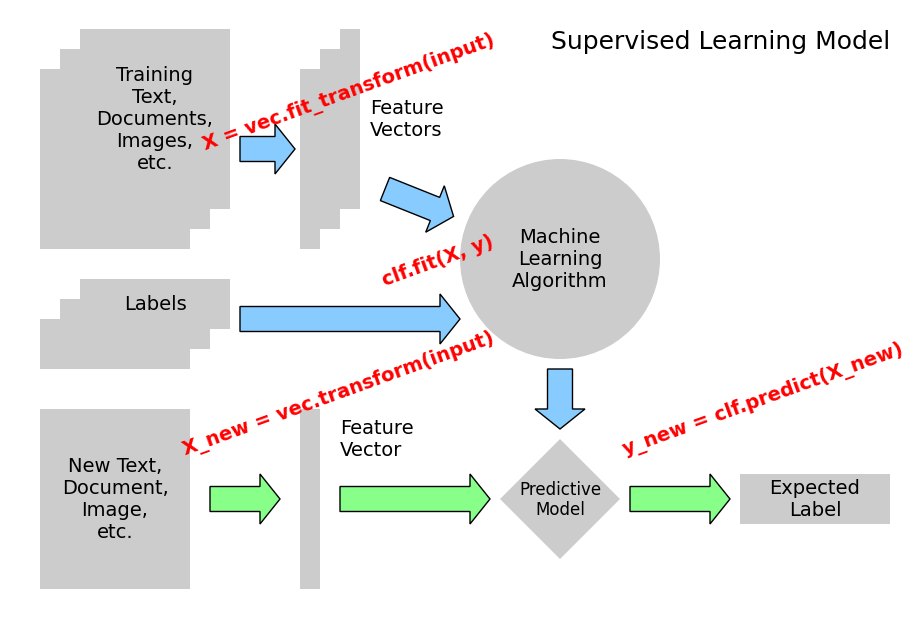

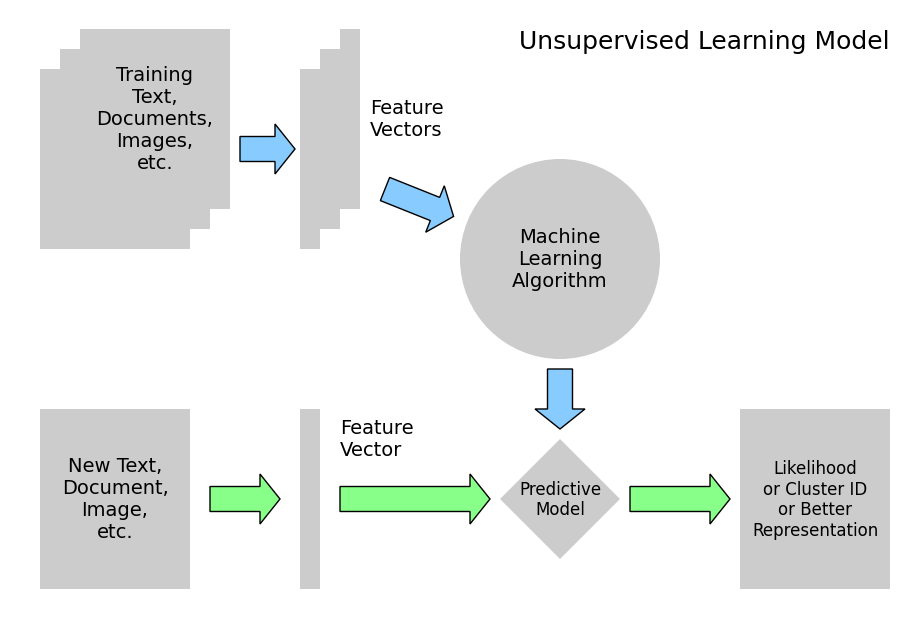

In [117]:
if __name__ == "__main__":
    plot_supervised_chart(False)
    plot_supervised_chart(True)
    plot_unsupervised_chart()

(compare-classifiers-on-the-digits-data)=

### Compare classifiers on the digits data

<!--- plot_compare_classifiers -->

Compare the performance of a variety of classifiers on a test set for the
digits data.

In [118]:
from sklearn import model_selection, datasets, metrics
from sklearn.svm import LinearSVC
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier

In [119]:
digits = datasets.load_digits()
X = digits.data
y = digits.target
X_train, X_test, y_train, y_test = model_selection.train_test_split(
    X, y, test_size=0.25, random_state=0
)

In [120]:
for Model in [LinearSVC, GaussianNB, KNeighborsClassifier]:
    clf = Model().fit(X_train, y_train)
    y_pred = clf.predict(X_test)
    print(f"{Model.__name__}: {metrics.f1_score(y_test, y_pred, average='macro')}")

LinearSVC: 0.9344942114287969
GaussianNB: 0.8332741681010102
KNeighborsClassifier: 0.9804562804949924


In [121]:
print("------------------")

------------------


In [122]:
# test SVC loss
for loss in ["hinge", "squared_hinge"]:
    clf = LinearSVC(loss=loss).fit(X_train, y_train)
    y_pred = clf.predict(X_test)
    print(
        f"LinearSVC(loss='{loss}'): {metrics.f1_score(y_test, y_pred, average='macro')}"
    )

LinearSVC(loss='hinge'): 0.9364016590755841
LinearSVC(loss='squared_hinge'): 0.9344942114287969


/home/runner/work/scientific-python-lectures/scientific-python-lectures/.venv/lib/python3.12/site-packages/sklearn/svm/_base.py:1258: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(


In [123]:
print("-------------------")

-------------------


In [124]:
# test the number of neighbors
for n_neighbors in range(1, 11):
    clf = KNeighborsClassifier(n_neighbors=n_neighbors).fit(X_train, y_train)
    y_pred = clf.predict(X_test)
    print(
        f"KNeighbors(n_neighbors={n_neighbors}): {metrics.f1_score(y_test, y_pred, average='macro')}"
    )

KNeighbors(n_neighbors=1): 0.9913675218842191
KNeighbors(n_neighbors=2): 0.9848442068835102
KNeighbors(n_neighbors=3): 0.9867753449543099
KNeighbors(n_neighbors=4): 0.9803719053818863
KNeighbors(n_neighbors=5): 0.9804562804949924
KNeighbors(n_neighbors=6): 0.9757924194139573
KNeighbors(n_neighbors=7): 0.9780645792142071
KNeighbors(n_neighbors=8): 0.9780645792142071


KNeighbors(n_neighbors=9): 0.9780645792142071
KNeighbors(n_neighbors=10): 0.9755550897728812


(the-eigenfaces-example-chaining-pca-and-svms)=

### The eigenfaces example: chaining PCA and SVMs

<!--- plot_eigenfaces -->

The goal of this example is to show how an unsupervised method and a
supervised one can be chained for better prediction. It starts with a
didactic but lengthy way of doing things, and finishes with the
idiomatic approach to pipelining in scikit-learn.

Here we'll take a look at a simple facial recognition example. Ideally,
we would use a dataset consisting of a subset of the [Labeled Faces in
the Wild](http://vis-www.cs.umass.edu/lfw) data that is available with
{func}`sklearn.datasets.fetch_lfw_people`. However, this is a relatively large
download (~200MB) so we will do the tutorial on a simpler, less rich dataset.
Feel free to explore the LFW dataset.

In [125]:
from sklearn import datasets

In [126]:
faces = datasets.fetch_olivetti_faces()
faces.data.shape

downloading Olivetti faces from https://ndownloader.figshare.com/files/5976027 to /home/runner/scikit_learn_data


(400, 4096)

Let's visualize these faces to see what we're working with

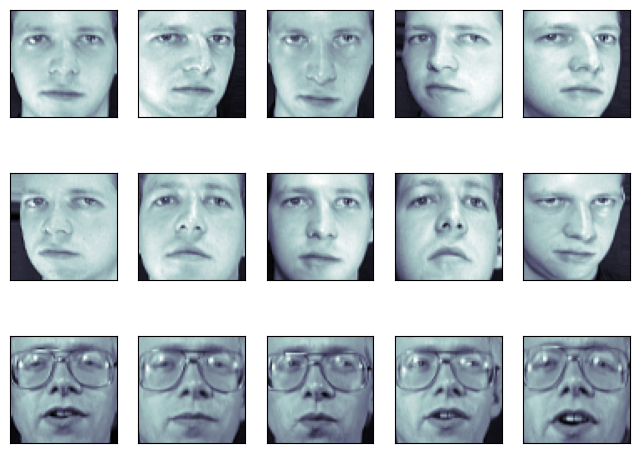

In [127]:
fig = plt.figure(figsize=(8, 6))
# plot several images
for i in range(15):
    ax = fig.add_subplot(3, 5, i + 1, xticks=[], yticks=[])
    ax.imshow(faces.images[i], cmap="bone")

::: {note}

Note that these faces have already been localized and scaled to a common size.
This is an important preprocessing piece for facial recognition, and is
a process that can require a large collection of training data. This can be
done in scikit-learn, but the challenge is gathering a sufficient amount of
training data for the algorithm to work. Fortunately, this piece is common
enough that it has been done. One good resource is [OpenCV](https://docs.opencv.org/2.4/modules/contrib/doc/facerec/facerec_tutorial.html)
— the _Open Computer Vision Library_.

:::

We'll perform a Support Vector classification of the images. We'll do a
typical train-test split on the images:

In [128]:
from sklearn.model_selection import train_test_split

In [129]:
X_train, X_test, y_train, y_test = train_test_split(
    faces.data, faces.target, random_state=0
)

In [130]:
print(X_train.shape, X_test.shape)

(300, 4096) (100, 4096)


### Preprocessing: Principal Component Analysis

1850 dimensions is a lot for SVM. We can use PCA to reduce these 1850
features to a manageable size, while maintaining most of the information
in the dataset.

In [131]:
from sklearn import decomposition

In [132]:
pca = decomposition.PCA(n_components=150, whiten=True)
pca.fit(X_train)

,"n_components n_components: int, float or 'mle', default=NoneNumber of components to keep.if n_components is not set all components are kept:: n_components == min(n_samples, n_features)If ``n_components == 'mle'`` and ``svd_solver == 'full'``, Minka'sMLE is used to guess the dimension. Use of ``n_components == 'mle'``will interpret ``svd_solver == 'auto'`` as ``svd_solver == 'full'``.If ``0 < n_components < 1`` and ``svd_solver == 'full'``, select thenumber of components such that the amount of variance that needs to beexplained is greater than the percentage specified by n_components.If ``svd_solver == 'arpack'``, the number of components must bestrictly less than the minimum of n_features and n_samples.Hence, the None case results in:: n_components == min(n_samples, n_features) - 1",150
,"copy copy: bool, default=TrueIf False, data passed to fit are overwritten and runningfit(X).transform(X) will not yield the expected results,use fit_transform(X) instead.",True
,"whiten whiten: bool, default=FalseWhen True (False by default) the `components_` vectors are multipliedby the square root of n_samples and then divided by the singular valuesto ensure uncorrelated outputs with unit component-wise variances.Whitening will remove some information from the transformed signal(the relative variance scales of the components) but can sometimeimprove the predictive accuracy of the downstream estimators bymaking their data respect some hard-wired assumptions.",True
,"svd_solver svd_solver: {'auto', 'full', 'covariance_eigh', 'arpack', 'randomized'}, default='auto'""auto"" : The solver is selected by a default 'auto' policy is based on `X.shape` and `n_components`: if the input data has fewer than 1000 features and more than 10 times as many samples, then the ""covariance_eigh"" solver is used. Otherwise, if the input data is larger than 500x500 and the number of components to extract is lower than 80% of the smallest dimension of the data, then the more efficient ""randomized"" method is selected. Otherwise the exact ""full"" SVD is computed and optionally truncated afterwards.""full"" : Run exact full SVD calling the standard LAPACK solver via `scipy.linalg.svd` and select the components by postprocessing""covariance_eigh"" : Precompute the covariance matrix (on centered data), run a classical eigenvalue decomposition on the covariance matrix typically using LAPACK and select the components by postprocessing. This solver is very efficient for n_samples >> n_features and small n_features. It is, however, not tractable otherwise for large n_features (large memory footprint required to materialize the covariance matrix). Also note that compared to the ""full"" solver, this solver effectively doubles the condition number and is therefore less numerical stable (e.g. on input data with a large range of singular values).""arpack"" : Run SVD truncated to `n_components` calling ARPACK solver via `scipy.sparse.linalg.svds`. It requires strictly `0 < n_components < min(X.shape)`""randomized"" : Run randomized SVD by the method of Halko et al... versionadded:: 0.18.0.. versionchanged:: 1.5 Added the 'covariance_eigh' solver.",'auto'
,"tol tol: float, default=0.0Tolerance for singular values computed by svd_solver == 'arpack'.Must be of range [0.0, infinity)... versionadded:: 0.18.0",0.0
,"iterated_power iterated_power: int or 'auto', default='auto'Number of iterations for the power method computed bysvd_solver == 'randomized'.Must be of range [0, infinity)... versionadded:: 0.18.0",'auto'
,"n_oversamples n_oversamples: int, default=10This parameter is only relevant when `svd_solver=""randomized""`.It corresponds to the additional number of random vectors to sample therange of `X` so as to ensure proper conditioning. See:func:`~sklearn.utils.extmath.randomized_svd` for more details... versionadded:: 1.1",10
,"power_iteration_normalizer power_iteration_normalizer: {'auto', 'QR', 'LU', 'none'}, default='auto'Power iteration normalizer for randomized SVD

One interesting part of PCA is that it computes the "mean" face, which
can be interesting to examine:

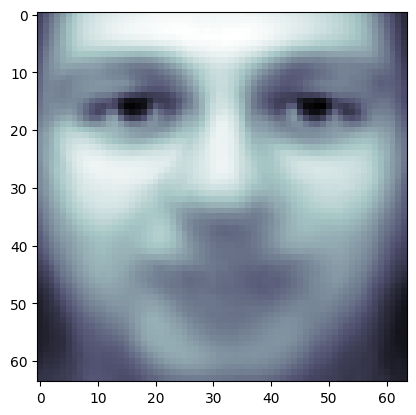

In [133]:
plt.imshow(pca.mean_.reshape(faces.images[0].shape), cmap="bone")

The principal components measure deviations about this mean along
orthogonal axes.

In [134]:
print(pca.components_.shape)

(150, 4096)


It is also interesting to visualize these principal components:

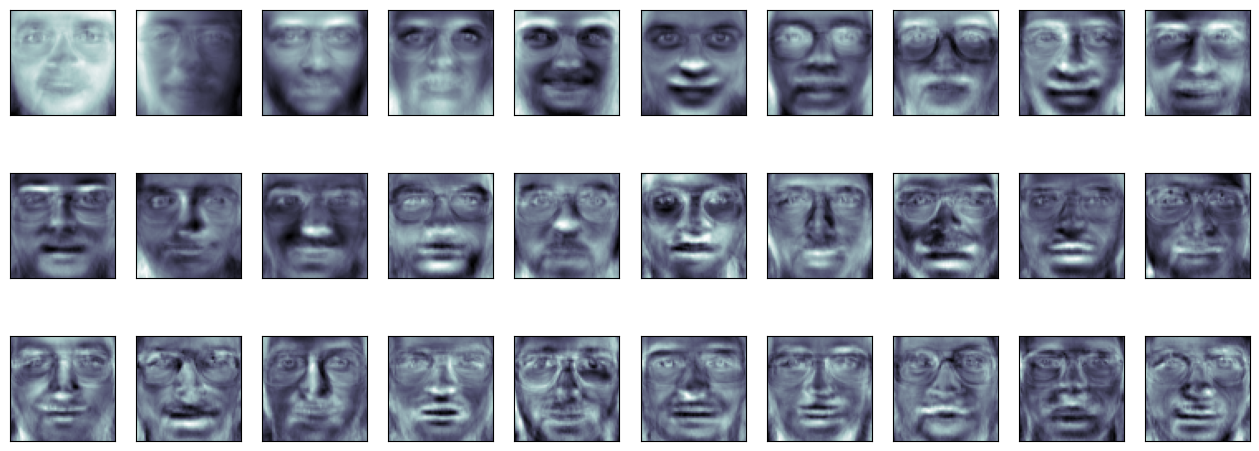

In [135]:
fig = plt.figure(figsize=(16, 6))
for i in range(30):
    ax = fig.add_subplot(3, 10, i + 1, xticks=[], yticks=[])
    ax.imshow(pca.components_[i].reshape(faces.images[0].shape), cmap="bone")

The components ("eigenfaces") are ordered by their importance from
top-left to bottom-right. We see that the first few components seem to
primarily take care of lighting conditions; the remaining components
pull out certain identifying features: the nose, eyes, eyebrows, etc.

With this projection computed, we can now project our original training
and test data onto the PCA basis:

In [136]:
X_train_pca = pca.transform(X_train)
X_test_pca = pca.transform(X_test)
print(X_train_pca.shape)
print(X_test_pca.shape)

(300, 150)
(100, 150)


These projected components correspond to factors in a linear combination
of component images such that the combination approaches the original
face.

### Doing the Learning: Support Vector Machines

Now we'll perform support-vector-machine classification on this reduced
dataset:

In [137]:
from sklearn import svm

In [138]:
clf = svm.SVC(C=5.0, gamma=0.001)
clf.fit(X_train_pca, y_train)

,"C C: float, default=1.0Regularization parameter. The strength of the regularization isinversely proportional to C. Must be strictly positive. The penaltyis a squared l2 penalty. For an intuitive visualization of the effectsof scaling the regularization parameter C, see:ref:`sphx_glr_auto_examples_svm_plot_svm_scale_c.py`.",5.0
,"kernel kernel: {'linear', 'poly', 'rbf', 'sigmoid', 'precomputed'} or callable, default='rbf'Specifies the kernel type to be used in the algorithm. Ifnone is given, 'rbf' will be used. If a callable is given it is used topre-compute the kernel matrix from data matrices; that matrix should bean array of shape ``(n_samples, n_samples)``. For an intuitivevisualization of different kernel types see:ref:`sphx_glr_auto_examples_svm_plot_svm_kernels.py`.",'rbf'
,"degree degree: int, default=3Degree of the polynomial kernel function ('poly').Must be non-negative. Ignored by all other kernels.",3
,"gamma gamma: {'scale', 'auto'} or float, default='scale'Kernel coefficient for 'rbf', 'poly' and 'sigmoid'.- if ``gamma='scale'`` (default) is passed then it uses 1 / (n_features * X.var()) as value of gamma,- if 'auto', uses 1 / n_features- if float, must be non-negative... versionchanged:: 0.22 The default value of ``gamma`` changed from 'auto' to 'scale'.",0.001
,"coef0 coef0: float, default=0.0Independent term in kernel function.It is only significant in 'poly' and 'sigmoid'.",0.0
,"shrinking shrinking: bool, default=TrueWhether to use the shrinking heuristic.See the :ref:`User Guide `.",True
,"probability probability: bool, default=FalseWhether to enable probability estimates. This must be enabled priorto calling `fit`, will slow down that method as it internally uses5-fold cross-validation, and `predict_proba` may be inconsistent with`predict`. Read more in the :ref:`User Guide `.",False
,"tol tol: float, default=1e-3Tolerance for stopping criterion.",0.001
,"cache_size cache_size: float, default=200Specify the size of the kernel cache (in MB).",200
,"class_weight class_weight: dict or 'balanced', default=NoneSet the parameter C of class i to class_weight[i]*C forSVC. If not given, all classes are supposed to haveweight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.",None
,"verbose verbose: bool, default=FalseEnable verbose output. Note that this setting takes advantage of aper-process runtime setting in libsvm that, if enabled, may not workproperly in a multithreaded context.",False


Finally, we can evaluate how well this classification did. First, we
might plot a few of the test-cases with the labels learned from the
training set:

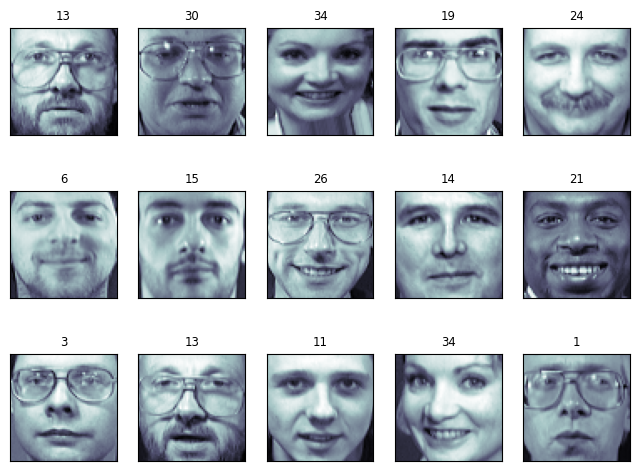

In [139]:
fig = plt.figure(figsize=(8, 6))
for i in range(15):
    ax = fig.add_subplot(3, 5, i + 1, xticks=[], yticks=[])
    ax.imshow(X_test[i].reshape(faces.images[0].shape), cmap="bone")
    y_pred = clf.predict(X_test_pca[i, np.newaxis])[0]
    color = "black" if y_pred == y_test[i] else "red"
    ax.set_title(y_pred, fontsize="small", color=color)

The classifier is correct on an impressive number of images given the
simplicity of its learning model! Using a linear classifier on 150
features derived from the pixel-level data, the algorithm correctly
identifies a large number of the people in the images.

Again, we can quantify this effectiveness using one of several measures
from {mod}`sklearn.metrics`. First we can do the classification
report, which shows the precision, recall and other measures of the
"goodness" of the classification:

In [140]:
from sklearn import metrics

In [141]:
y_pred = clf.predict(X_test_pca)
print(metrics.classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       1.00      0.50      0.67         6
           1       1.00      1.00      1.00         4
           2       0.50      1.00      0.67         2
           3       1.00      1.00      1.00         1
           4       0.33      1.00      0.50         1
           5       1.00      1.00      1.00         5
           6       1.00      1.00      1.00         4
           7       1.00      0.67      0.80         3
           9       1.00      1.00      1.00         1
          10       1.00      1.00      1.00         4
          11       1.00      1.00      1.00         1
          12       1.00      1.00      1.00         2
          13       1.00      1.00      1.00         3
          14       1.00      1.00      1.00         5
          15       0.75      1.00      0.86         3
          17       1.00      1.00      1.00         6
          19       1.00      1.00      1.00         4
          20       1.00    

Another interesting metric is the _confusion matrix_, which indicates
how often any two items are mixed-up. The confusion matrix of a perfect
classifier would only have nonzero entries on the diagonal, with zeros
on the off-diagonal:

In [142]:
print(metrics.confusion_matrix(y_test, y_pred))

[[3 0 0 ... 0 0 0]
 [0 4 0 ... 0 0 0]
 [0 0 2 ... 0 0 0]
 ...
 [0 0 0 ... 3 0 0]
 [0 0 0 ... 0 1 0]
 [0 0 0 ... 0 0 3]]


### Pipelining

Above we used PCA as a pre-processing step before applying our support
vector machine classifier. Plugging the output of one estimator directly
into the input of a second estimator is a commonly used pattern; for
this reason scikit-learn provides a `Pipeline` object which automates
this process. The above problem can be re-expressed as a pipeline as
follows:

In [143]:
from sklearn.pipeline import Pipeline

In [144]:
clf = Pipeline(
    [
        ("pca", decomposition.PCA(n_components=150, whiten=True)),
        ("svm", svm.LinearSVC(C=1.0)),
    ]
)

In [145]:
clf.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators ` for more details.","[('pca', ...), ('svm', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing `.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"n_components n_components: int, float or 'mle', default=NoneNumber of components to keep.if n_components is not set all components are kept:: n_components == min(n_samples, n_features)If ``n_components == 'mle'`` and ``svd_solver == 'full'``, Minka'sMLE is used to guess the dimension. Use of ``n_components == 'mle'``will interpret ``svd_solver == 'auto'`` as ``svd_solver == 'full'``.If ``0 < n_components < 1`` and ``svd_solver == 'full'``, select thenumber of components such that the amount of variance that needs to beexplained is greater than the percentage specified by n_components.If ``svd_solver == 'arpack'``, the number of components must bestrictly less than the minimum of n_features and n_samples.Hence, the None case results in:: n_components == min(n_samples, n_features) - 1",150
,"copy copy: bool, default=TrueIf False, data passed to fit are overwritten and runningfit(X).transform(X) will not yield the expected results,use fit_transform(X) instead.",True
,"whiten whiten: bool, default=FalseWhen True (False by default) the `components_` vectors are multipliedby the square root of n_samples and then divided by the singular valuesto ensure uncorrelated outputs with unit component-wise variances.Whitening will remove some information from the transformed signal(the relative variance scales of the components) but can sometimeimprove the predictive accuracy of the downstream estimators bymaking their data respect some hard-wired assumptions.",True
,"svd_solver svd_solver: {'auto', 'full', 'covariance_eigh', 'arpack', 'randomized'}, default='auto'""auto"" : The solver is selected by a default 'auto' policy is based on `X.shape` and `n_components`: if the input data has fewer than 1000 features and more than 10 times as many samples, then the ""covariance_eigh"" solver is used. Otherwise, if the input data is larger than 500x500 and the number of components to extract is lower than 80% of the smallest dimension of the data, then the more efficient ""randomized"" method is selected. Otherwise the exact ""full"" SVD is computed and optionally truncated afterwards.""full"" : Run exact full SVD calling the standard LAPACK solver via `scipy.linal

In [146]:
y_pred = clf.predict(X_test)
print(metrics.confusion_matrix(y_pred, y_test))

[[5 0 0 ... 0 0 0]
 [0 4 0 ... 0 0 0]
 [0 0 1 ... 0 0 0]
 ...
 [0 0 0 ... 3 0 0]
 [0 0 0 ... 0 1 0]
 [0 0 0 ... 0 0 3]]


### A Note on Facial Recognition

Here we have used PCA "eigenfaces" as a pre-processing step for facial
recognition. The reason we chose this is because PCA is a
broadly-applicable technique, which can be useful for a wide array of
data types. Research in the field of facial recognition in particular,
however, has shown that other more specific feature extraction methods
are can be much more effective.

(example-of-linear-and-non-linear-models)=

### Example of linear and non-linear models

<!--- plot_svm_non_linear -->

This is an example plot from the tutorial which accompanies an explanation
of the support vector machine GUI.

In [147]:
from sklearn import svm

In [148]:
rng = np.random.default_rng(27446968)

Data that is linearly separable

In [149]:
def linear_model(rseed=42, n_samples=30):
    "Generate data according to a linear model"
    np.random.seed(rseed)

    data = np.random.normal(0, 10, (n_samples, 2))
    data[: n_samples // 2] -= 15
    data[n_samples // 2 :] += 15

    labels = np.ones(n_samples)
    labels[: n_samples // 2] = -1

    return data, labels

In [150]:
X, y = linear_model()
clf = svm.SVC(kernel="linear")
clf.fit(X, y)

,"C C: float, default=1.0Regularization parameter. The strength of the regularization isinversely proportional to C. Must be strictly positive. The penaltyis a squared l2 penalty. For an intuitive visualization of the effectsof scaling the regularization parameter C, see:ref:`sphx_glr_auto_examples_svm_plot_svm_scale_c.py`.",1.0
,"kernel kernel: {'linear', 'poly', 'rbf', 'sigmoid', 'precomputed'} or callable, default='rbf'Specifies the kernel type to be used in the algorithm. Ifnone is given, 'rbf' will be used. If a callable is given it is used topre-compute the kernel matrix from data matrices; that matrix should bean array of shape ``(n_samples, n_samples)``. For an intuitivevisualization of different kernel types see:ref:`sphx_glr_auto_examples_svm_plot_svm_kernels.py`.",'linear'
,"degree degree: int, default=3Degree of the polynomial kernel function ('poly').Must be non-negative. Ignored by all other kernels.",3
,"gamma gamma: {'scale', 'auto'} or float, default='scale'Kernel coefficient for 'rbf', 'poly' and 'sigmoid'.- if ``gamma='scale'`` (default) is passed then it uses 1 / (n_features * X.var()) as value of gamma,- if 'auto', uses 1 / n_features- if float, must be non-negative... versionchanged:: 0.22 The default value of ``gamma`` changed from 'auto' to 'scale'.",'scale'
,"coef0 coef0: float, default=0.0Independent term in kernel function.It is only significant in 'poly' and 'sigmoid'.",0.0
,"shrinking shrinking: bool, default=TrueWhether to use the shrinking heuristic.See the :ref:`User Guide `.",True
,"probability probability: bool, default=FalseWhether to enable probability estimates. This must be enabled priorto calling `fit`, will slow down that method as it internally uses5-fold cross-validation, and `predict_proba` may be inconsistent with`predict`. Read more in the :ref:`User Guide `.",False
,"tol tol: float, default=1e-3Tolerance for stopping criterion.",0.001
,"cache_size cache_size: float, default=200Specify the size of the kernel cache (in MB).",200
,"class_weight class_weight: dict or 'balanced', default=NoneSet the parameter C of class i to class_weight[i]*C forSVC. If not given, all classes are supposed to haveweight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.",None
,"verbose verbose: bool, default=FalseEnable verbose output. Note that this setting takes advantage of aper-process runtime setting in libsvm that, if enabled, may not workproperly in a multithreaded context.",False


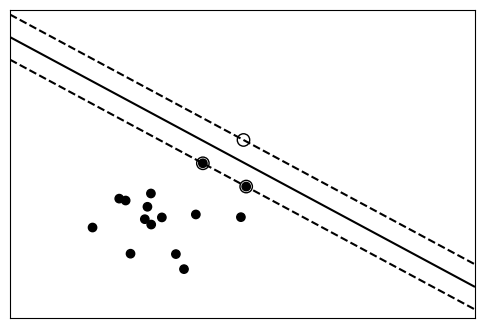

In [151]:
plt.figure(figsize=(6, 4))
ax = plt.subplot(111, xticks=[], yticks=[])
ax.scatter(X[:, 0], X[:, 1], c=y, cmap="bone")
ax.scatter(
    clf.support_vectors_[:, 0],
    clf.support_vectors_[:, 1],
    s=80,
    edgecolors="k",
    facecolors="none",
)
delta = 1
y_min, y_max = -50, 50
x_min, x_max = -50, 50
x = np.arange(x_min, x_max + delta, delta)
y = np.arange(y_min, y_max + delta, delta)
X1, X2 = np.meshgrid(x, y)
Z = clf.decision_function(np.c_[X1.ravel(), X2.ravel()])
Z = Z.reshape(X1.shape)
ax.contour(
    X1, X2, Z, [-1.0, 0.0, 1.0], colors="k", linestyles=["dashed", "solid", "dashed"]
)

Data with a non-linear separation

In [152]:
def nonlinear_model(rseed=27446968, n_samples=30):
    rng = np.random.default_rng(rseed)

    radius = 40 * rng.random(n_samples)
    far_pts = radius > 20
    radius[far_pts] *= 1.2
    radius[~far_pts] *= 1.1

    theta = rng.random(n_samples) * np.pi * 2

    data = np.empty((n_samples, 2))
    data[:, 0] = radius * np.cos(theta)
    data[:, 1] = radius * np.sin(theta)

    labels = np.ones(n_samples)
    labels[far_pts] = -1

    return data, labels

In [153]:
X, y = nonlinear_model()
clf = svm.SVC(kernel="rbf", gamma=0.001, coef0=0, degree=3)
clf.fit(X, y)

,"C C: float, default=1.0Regularization parameter. The strength of the regularization isinversely proportional to C. Must be strictly positive. The penaltyis a squared l2 penalty. For an intuitive visualization of the effectsof scaling the regularization parameter C, see:ref:`sphx_glr_auto_examples_svm_plot_svm_scale_c.py`.",1.0
,"kernel kernel: {'linear', 'poly', 'rbf', 'sigmoid', 'precomputed'} or callable, default='rbf'Specifies the kernel type to be used in the algorithm. Ifnone is given, 'rbf' will be used. If a callable is given it is used topre-compute the kernel matrix from data matrices; that matrix should bean array of shape ``(n_samples, n_samples)``. For an intuitivevisualization of different kernel types see:ref:`sphx_glr_auto_examples_svm_plot_svm_kernels.py`.",'rbf'
,"degree degree: int, default=3Degree of the polynomial kernel function ('poly').Must be non-negative. Ignored by all other kernels.",3
,"gamma gamma: {'scale', 'auto'} or float, default='scale'Kernel coefficient for 'rbf', 'poly' and 'sigmoid'.- if ``gamma='scale'`` (default) is passed then it uses 1 / (n_features * X.var()) as value of gamma,- if 'auto', uses 1 / n_features- if float, must be non-negative... versionchanged:: 0.22 The default value of ``gamma`` changed from 'auto' to 'scale'.",0.001
,"coef0 coef0: float, default=0.0Independent term in kernel function.It is only significant in 'poly' and 'sigmoid'.",0
,"shrinking shrinking: bool, default=TrueWhether to use the shrinking heuristic.See the :ref:`User Guide `.",True
,"probability probability: bool, default=FalseWhether to enable probability estimates. This must be enabled priorto calling `fit`, will slow down that method as it internally uses5-fold cross-validation, and `predict_proba` may be inconsistent with`predict`. Read more in the :ref:`User Guide `.",False
,"tol tol: float, default=1e-3Tolerance for stopping criterion.",0.001
,"cache_size cache_size: float, default=200Specify the size of the kernel cache (in MB).",200
,"class_weight class_weight: dict or 'balanced', default=NoneSet the parameter C of class i to class_weight[i]*C forSVC. If not given, all classes are supposed to haveweight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.",None
,"verbose verbose: bool, default=FalseEnable verbose output. Note that this setting takes advantage of aper-process runtime setting in libsvm that, if enabled, may not workproperly in a multithreaded context.",False


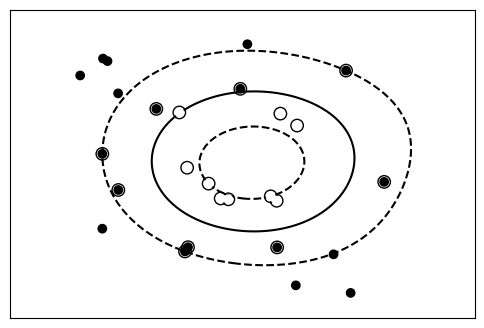

In [154]:
plt.figure(figsize=(6, 4))
ax = plt.subplot(1, 1, 1, xticks=[], yticks=[])
ax.scatter(X[:, 0], X[:, 1], c=y, cmap="bone", zorder=2)
ax.scatter(
    clf.support_vectors_[:, 0],
    clf.support_vectors_[:, 1],
    s=80,
    edgecolors="k",
    facecolors="none",
)
delta = 1
y_min, y_max = -50, 50
x_min, x_max = -50, 50
x = np.arange(x_min, x_max + delta, delta)
y = np.arange(y_min, y_max + delta, delta)
X1, X2 = np.meshgrid(x, y)
Z = clf.decision_function(np.c_[X1.ravel(), X2.ravel()])
Z = Z.reshape(X1.shape)
ax.contour(
    X1,
    X2,
    Z,
    [-1.0, 0.0, 1.0],
    colors="k",
    linestyles=["dashed", "solid", "dashed"],
    zorder=1,
)

(variance-linear-regr)=

### variance_linear_regr

<!--- plot_variance_linear_regr -->

Plot variance and regularization in linear models

In [155]:
# Smaller figures

In [156]:
plt.rcParams["figure.figsize"] = (3, 2)

In [157]:
# We consider the situation where we have only 2 data point
X = np.c_[0.5, 1].T
y = [0.5, 1]
X_test = np.c_[0, 2].T

In [158]:
# Without noise, as linear regression fits the data perfectly
from sklearn import linear_model

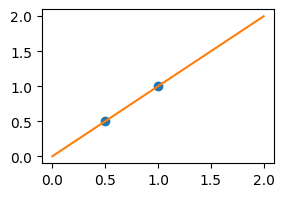

In [159]:
regr = linear_model.LinearRegression()
regr.fit(X, y)
plt.plot(X, y, "o")
plt.plot(X_test, regr.predict(X_test))

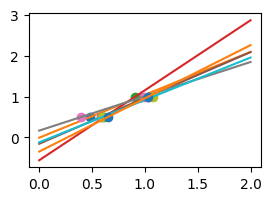

In [160]:
# In real life situation, we have noise (e.g. measurement noise) in our data:
rng = np.random.default_rng(27446968)
for _ in range(6):
    noisy_X = X + np.random.normal(loc=0, scale=0.1, size=X.shape)
    plt.plot(noisy_X, y, "o")
    regr.fit(noisy_X, y)
    plt.plot(X_test, regr.predict(X_test))

As we can see, our linear model captures and amplifies the noise in the
data. It displays a lot of variance.

We can use another linear estimator that uses regularization, the
{class}`~sklearn.linear_model.Ridge` estimator. This estimator regularizes the
coefficients by shrinking them to zero, under the assumption that very high
correlations are often spurious. The alpha parameter controls the amount of
shrinkage used.

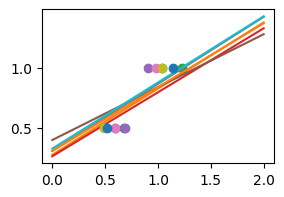

In [161]:
regr = linear_model.Ridge(alpha=0.1)
np.random.seed(0)
for _ in range(6):
    noisy_X = X + np.random.normal(loc=0, scale=0.1, size=X.shape)
    plt.plot(noisy_X, y, "o")
    regr.fit(noisy_X, y)
    plt.plot(X_test, regr.predict(X_test))